# Lecture 8: Recurrent Networks and Neural ODEs

Two questions about time:

1. **Memory.** If the model does not see the whole state, can past frames make up for it? We remove velocity from the BubbleML input and compare a 4-frame SmallCNN with a ConvGRU.
2. **Continuous time.** A neural ODE learns $du/dt = f_\theta(u)$ and can be evaluated at any time. We train one on the Lecture 1 heat equation and evaluate it between the training frames, then count solver function evaluations as the diffusivity grows.

This notebook uses `torchdiffeq` for ODE solvers. The next cell installs it.

In [1]:
%pip install -q torchdiffeq

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import time
import urllib.request
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchdiffeq import odeint

device = torch.device("mps" if torch.backends.mps.is_available() else "cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)
torch.manual_seed(0)

DATA_DIR = "../data/bubbleml"
FILE = "bubbleml2_Twall106_128.npz"
URL = "https://raw.githubusercontent.com/eecs-ml4sci/eecs-ml4sci.github.io/main/data/bubbleml/"
os.makedirs(DATA_DIR, exist_ok=True)
if not os.path.exists(os.path.join(DATA_DIR, FILE)):
    print("downloading", FILE)
    urllib.request.urlretrieve(URL + FILE, os.path.join(DATA_DIR, FILE))

# temperature colormap from Lecture 1 (https://github.com/therml-ai/boiling-viz), for theta in [0, 1]
temp_cmap = LinearSegmentedColormap.from_list("temp_green", list(zip(
    [0.0, 0.02, 0.04, 0.06, 0.08, 0.1, 0.134, 0.167, 0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0],
    ["#0000FF", "#0443FF", "#0E7AFF", "#16B4FF", "#1FF1FF", "#21FFD3", "#22FF9B", "#22FF67", "#22FF15", "#29FF06",
     "#45FF07", "#6DFF08", "#9EFF09", "#D4FF0A", "#FEF30A", "#FEB709", "#FD7D08", "#FC4908", "#FC1407", "#FB0007"])))

Using device: mps


---
## Part 1: Memory on BubbleML

### The data

BubbleML_2, subcooled pool boiling of FC-72 with a 106 °C heater (the Lecture 6 and 7 file), averaged to 64 × 64.
Frames are 0.2 nondimensional time units apart. Channels: $\theta = (T - 50\,°\mathrm{C})/(106\,°\mathrm{C} - 50\,°\mathrm{C})$ and the velocity $u, v$.
The first 600 frames are for training and the last 200 for testing.

In Lecture 7 the model received θ, u and v, and extra input frames did not help. Here the model receives **θ only**.
Velocity is part of the state it does not see; it has to infer the flow from how the temperature changes from frame to frame.

In [3]:
d = np.load(os.path.join(DATA_DIR, FILE))
data = np.stack([d["temperature"], d["velx"], d["vely"]], axis=1).astype(np.float32)   # [frames, 3, 128, 128]
data = data.reshape(len(data), 3, 64, 2, 64, 2).mean(axis=(3, 5))                       # 2 x 2 average -> 64 x 64
train_np, test_np = data[:600], data[600:]
mu, sd = train_np.mean(axis=(0, 2, 3)), train_np.std(axis=(0, 2, 3))
du = train_np[1:] - train_np[:-1]
mu_du, sd_du = du.mean(axis=(0, 2, 3)), du.std(axis=(0, 2, 3))
train_t = torch.from_numpy(train_np)
H = 4      # frames of history: the stack length, and the number of true frames used to warm up the ConvGRU
print("train:", train_np.shape, "  test:", test_np.shape)

train: (600, 3, 64, 64)   test: (201, 3, 64, 64)


### Two models with memory

* **`Stack(c, k)`**: SmallCNN (four 3 × 3 convolutions) on the last $k$ frames, stacked as channels. `k = 1` is the Lecture 7 model.
* **`ConvGRU(c)`**: a 3 × 3 convolution encoder, a convolutional GRU cell with 20 hidden channels, and a decoder of two 3 × 3 convolutions.
  The GRU update is

$$z_n = \sigma(W_z * [h_{n-1}, e_n]),\quad r_n = \sigma(W_r * [h_{n-1}, e_n]),\quad h_n = (1 - z_n) \odot h_{n-1} + z_n \odot \tanh(W * [r_n \odot h_{n-1}, e_n]),$$

where $e_n$ is the encoded input and $*$ is a 3 × 3 convolution. One step has a 9 × 9 receptive field, like SmallCNN.

Both predict the standardized change of the input fields (Lecture 4). `c` is the number of input channels: 1 for θ only, 3 for θ, u, v.

In [4]:
def conv(i, o):
    return nn.Conv2d(i, o, 3, padding=1)

class Base(nn.Module):
    # standardization buffers for the first c channels
    def __init__(self, c):
        super().__init__()
        self.c = c
        self.register_buffer("mu", torch.tensor(mu[:c]).view(1, c, 1, 1))
        self.register_buffer("sd", torch.tensor(sd[:c]).view(1, c, 1, 1))
        self.register_buffer("mu_du", torch.tensor(mu_du[:c]).view(1, c, 1, 1))
        self.register_buffer("sd_du", torch.tensor(sd_du[:c]).view(1, c, 1, 1))
    def std(self, x):
        return (x - self.mu) / self.sd
    def nxt(self, x, inc):                     # next state from the standardized change
        return x + self.mu_du + self.sd_du * inc

class Stack(Base):
    def __init__(self, c, k, hidden=32):
        super().__init__(c)
        self.k = k
        self.net = nn.Sequential(conv(c * k, hidden), nn.GELU(), conv(hidden, hidden), nn.GELU(),
                                 conv(hidden, hidden), nn.GELU(), conv(hidden, c))
    def inc(self, xs):                         # xs: [batch, k, c, 64, 64], oldest frame first
        return self.net(self.std(xs).flatten(1, 2))

class ConvGRU(Base):
    def __init__(self, c, hidden=20):
        super().__init__(c)
        self.h = hidden
        self.enc = conv(c, hidden)
        self.gates = conv(2 * hidden, 2 * hidden)       # update gate z and reset gate r
        self.cand = conv(2 * hidden, hidden)            # candidate state
        self.dec = nn.Sequential(conv(hidden, 32), nn.GELU(), conv(32, c))
    def step(self, x, h):                       # one time step: returns the standardized change and the new hidden state
        e = F.gelu(self.enc(self.std(x)))
        if h is None:
            h = torch.zeros(x.shape[0], self.h, *x.shape[-2:], device=x.device)
        z, r = torch.sigmoid(self.gates(torch.cat([e, h], 1))).chunk(2, 1)
        h_cand = torch.tanh(self.cand(torch.cat([e, r * h], 1)))
        h = (1 - z) * h + z * h_cand
        return self.dec(h), h

def nparams(m):
    return sum(p.numel() for p in m.parameters())

print("parameters:  1 frame", nparams(Stack(1, 1)), "  4 frames", nparams(Stack(1, H)), "  ConvGRU", nparams(ConvGRU(1)))

parameters:  1 frame 19105   4 frames 19969   ConvGRU 27941


### Training

* **Stack**: one-step pairs, as in Lecture 7.
* **ConvGRU**: windows of `W = 10` frames with teacher forcing (the true frame is the input at every step).
  The first `H - 1` steps only warm up the hidden state; the loss is on the remaining predictions.
  The gradient flows back through the whole window: backpropagation through time.

Same number of optimizer steps for every model. A ConvGRU step costs about `W` times more than a SmallCNN step.

In [5]:
STEPS = 400      # the slides used 2000; increase it if you have time
W = 10

def train(kind, c, steps=STEPS, batch=16, seed=0):
    torch.manual_seed(seed); g = np.random.default_rng(seed)
    m = (Stack(c, 1) if kind == "1 frame" else Stack(c, H) if kind == f"{H} frames" else ConvGRU(c)).to(device)
    opt = torch.optim.Adam(m.parameters(), lr=1e-3)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, steps)
    t0 = time.time()
    for step in range(steps):
        if kind == "ConvGRU":
            i = g.integers(0, len(train_t) - W, batch)
            seq = torch.stack([train_t[j:j + W, :c] for j in i]).to(device)     # [batch, W, c, 64, 64]
            h, loss = None, 0.0
            for t in range(W - 1):
                out, h = m.step(seq[:, t], h)
                if t >= H - 1:
                    target = (seq[:, t + 1] - seq[:, t] - m.mu_du) / m.sd_du
                    loss = loss + F.mse_loss(out, target)
            loss = loss / (W - H)
        else:
            i = g.integers(0, len(train_t) - m.k, batch)
            xs = torch.stack([train_t[j:j + m.k, :c] for j in i]).to(device)
            y = torch.stack([train_t[j + m.k, :c] for j in i]).to(device)
            target = (y - xs[:, -1] - m.mu_du) / m.sd_du
            loss = F.mse_loss(m.inc(xs), target)
        opt.zero_grad(); loss.backward(); opt.step(); sched.step()
        if step % 100 == 0:
            print(f"  {kind:9s} step {step:4d}  loss {loss.item():.3f}  ({time.time() - t0:.0f} s)")
    return m.eval()

@torch.no_grad()
def rollout(m, c, steps=195):
    # start at test frame H - 1, after H true frames; then feed predictions back
    T = torch.from_numpy(test_np[:, :c]).to(device)
    if isinstance(m, ConvGRU):
        h = None
        for t in range(H - 1):
            _, h = m.step(T[t:t + 1], h)
        x = T[H - 1:H]; out = [x[0, 0].cpu().numpy()]
        for _ in range(steps):
            inc, h = m.step(x, h); x = m.nxt(x, inc); out.append(x[0, 0].cpu().numpy())
    else:
        hist = [T[t:t + 1] for t in range(H - m.k, H)]; out = [hist[-1][0, 0].cpu().numpy()]
        for _ in range(steps):
            x = m.nxt(hist[-1], m.inc(torch.stack(hist[-m.k:], 1))); hist.append(x); out.append(x[0, 0].cpu().numpy())
    return np.stack(out)

def rel_err(roll):
    t = test_np[H - 1:H - 1 + len(roll), 0]
    return np.linalg.norm((roll - t).reshape(len(roll), -1), axis=1) / np.linalg.norm(t.reshape(len(roll), -1), axis=1)

In [6]:
models = {k: train(k, c=1) for k in ["1 frame", f"{H} frames", "ConvGRU"]}
rolls = {k: rollout(m, c=1) for k, m in models.items()}

  1 frame   step    0  loss 0.990  (0 s)
  1 frame   step  100  loss 0.617  (1 s)
  1 frame   step  200  loss 0.612  (3 s)
  1 frame   step  300  loss 0.623  (5 s)
  4 frames  step    0  loss 0.971  (0 s)
  4 frames  step  100  loss 0.497  (2 s)
  4 frames  step  200  loss 0.475  (4 s)
  4 frames  step  300  loss 0.439  (5 s)
  ConvGRU   step    0  loss 0.988  (0 s)
  ConvGRU   step  100  loss 0.498  (15 s)
  ConvGRU   step  200  loss 0.405  (29 s)
  ConvGRU   step  300  loss 0.396  (43 s)


### One-step error

Each model gets true frames as input and predicts one step. This measures what the model can infer from its input, without the error growth of a rollout.
The ConvGRU reads the true test frames in order, so its hidden state always holds the true history.

In [7]:
@torch.no_grad()
def one_step(m, c=1):
    T = torch.from_numpy(test_np[:, :c]).to(device)
    preds = []
    if isinstance(m, ConvGRU):
        h = None
        for t in range(len(T) - 1):
            inc, h = m.step(T[t:t + 1], h)
            if t >= H - 1:
                preds.append(m.nxt(T[t:t + 1], inc))
    else:
        for t in range(H - 1, len(T) - 1):
            preds.append(m.nxt(T[t:t + 1], m.inc(T[t + 1 - m.k:t + 1][None])))
    p = torch.cat(preds)[:, 0].cpu().numpy()
    true = test_np[H:, 0]
    return np.mean(np.linalg.norm((p - true).reshape(len(p), -1), axis=1) / np.linalg.norm(true.reshape(len(p), -1), axis=1))

err1 = {k: one_step(m) for k, m in models.items()}
for k, e in err1.items():
    print(f"{k:9s} one-step relative error of θ: {e:.4f}")

1 frame   one-step relative error of θ: 0.2697
4 frames  one-step relative error of θ: 0.2285
ConvGRU   one-step relative error of θ: 0.2187


### Rollout

Now each model feeds its predictions back as input. Every model drifts eventually, so we look at the first 30 steps, on a log scale, and at the fields after a few steps.

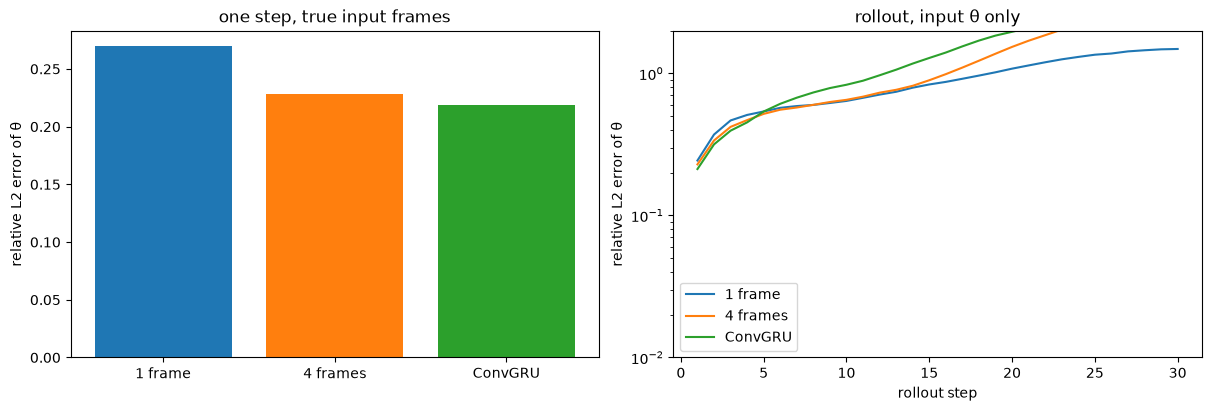

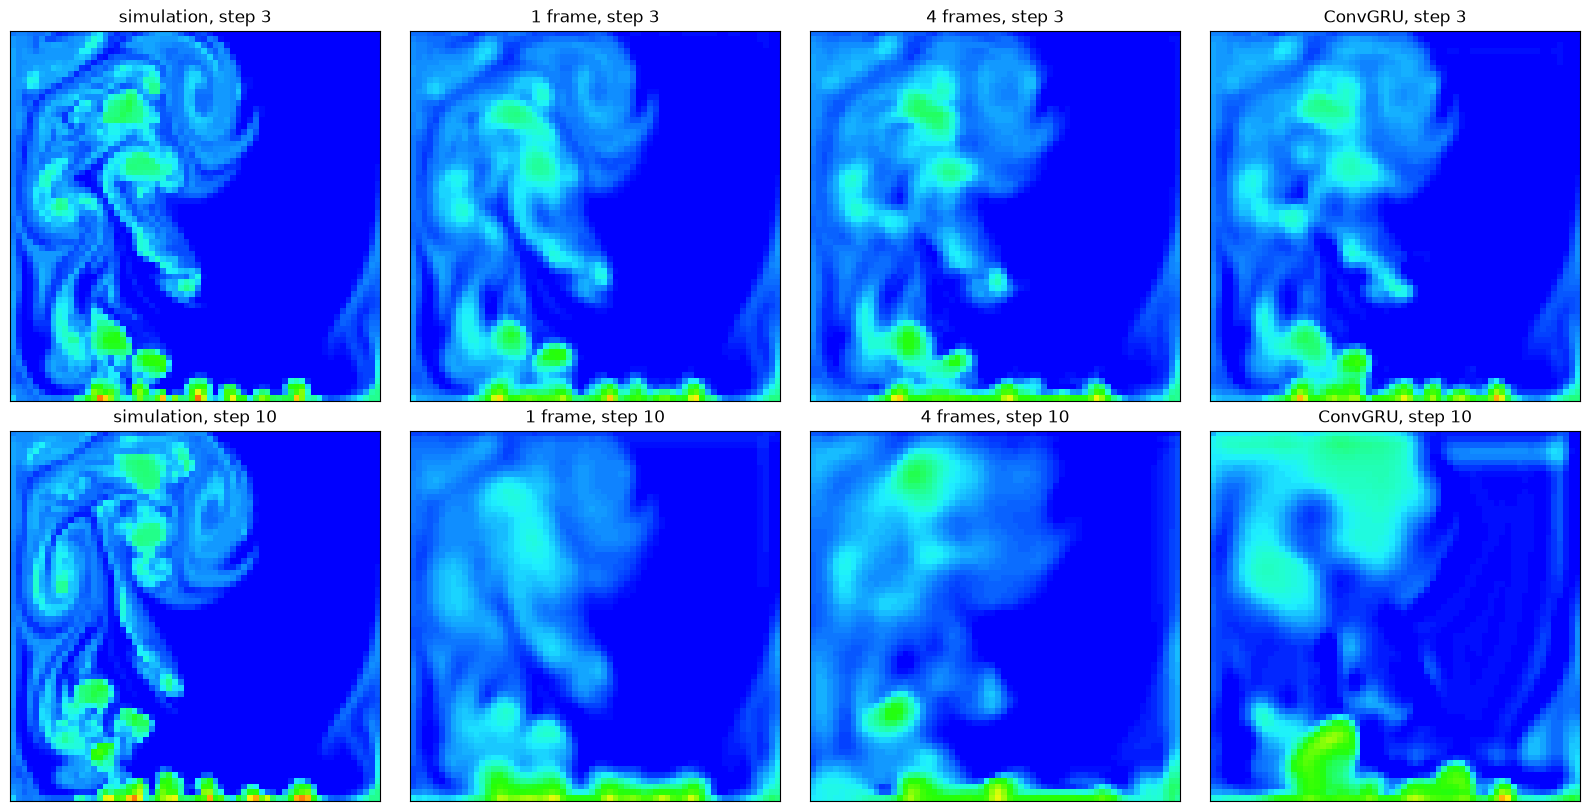

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
ax[0].bar(list(err1), list(err1.values()), color=["C0", "C1", "C2"])
ax[0].set_ylabel("relative L2 error of θ"); ax[0].set_title("one step, true input frames")
N = 30
for k, r in rolls.items():
    ax[1].semilogy(range(1, N + 1), rel_err(r)[1:N + 1], label=k)
ax[1].set_ylim(1e-2, 2)
ax[1].set_xlabel("rollout step"); ax[1].set_ylabel("relative L2 error of θ"); ax[1].legend(); ax[1].set_title("rollout, input θ only")
plt.show()

fig, ax = plt.subplots(2, 4, figsize=(16, 8), layout="constrained")
for row, n in enumerate([3, 10]):
    panels = [(test_np[H - 1 + n, 0], "simulation")] + [(rolls[k][n], k) for k in rolls]
    for a, (f, t) in zip(ax[row], panels):
        a.imshow(f, cmap=temp_cmap, vmin=0, vmax=1, origin="lower"); a.set_title(f"{t}, step {n}"); a.set_xticks([]); a.set_yticks([])
plt.show()

**What to observe**

* One-step error: do the 4-frame window and the ConvGRU beat the 1-frame model? All three see θ only, so the gain comes from what past frames reveal about the velocity.
* Rollout: how many steps does the gain last? After about 5 steps the memory models are no better than the 1-frame model, and can be worse. By step 10 the thin plumes are gone in all three, and by a few dozen steps none of the rollouts is usable. Memory improves each step's input; it does not fix the rollout drift of Lecture 7. For that you would add pushforward or unrolled training.
* With `STEPS = 400` the numbers are noisier than on the slides. If the ranking surprises you, train longer or try another seed before drawing a conclusion.
* **Try it:** train the three models with `c=3` (θ, u, v) and compare the one-step errors. Does the history still help when the velocity is in the input?

---
## Part 2: A neural ODE for the heat equation

The Lecture 1 heat equation, $\partial u/\partial t = \alpha \nabla^2 u$ on $[0,1]^2$ with $u = 0$ on the boundary, solved exactly as a sum of decaying sine modes.
This time the frames are **5 times further apart** than in Lecture 1: $\Delta t = 2.5 \times 10^{-3}$.

The neural ODE is $du/dt = f_\theta(u)$ with $f_\theta$ a small CNN on the grid (method of lines). We set $f_\theta$ to zero on the boundary cells, which keeps $u = 0$ there, and start the last convolution at zero, so the untrained model is $du/dt = 0$.
We train it on segments of 3 frames: start from the first frame, integrate with an adaptive solver (Dormand-Prince, `dopri5`), and compare with the next 2 frames.
The gradient is computed by backpropagating through the solver.

In [9]:
N, alpha, K = 48, 1.0, 6
dt, T = 2.5e-3, 20
rng = np.random.default_rng(0)
x = np.linspace(0, 1, N); X, Y = np.meshgrid(x, x)

def coeffs():
    return {(m, n): rng.normal() / (m**2 + n**2) for m in range(1, K + 1) for n in range(1, K + 1)}

def field(a, t):
    u = np.zeros((len(t), N, N)); t = np.asarray(t)[:, None, None]
    for (m, n), c in a.items():
        u += c * np.sin(m * np.pi * X) * np.sin(n * np.pi * Y) * np.exp(-alpha * np.pi**2 * (m**2 + n**2) * t)
    return u.astype(np.float32)

frames = np.arange(T + 1) * dt
heat_train = torch.from_numpy(np.stack([field(coeffs(), frames) for _ in range(100)]))      # [100, 21, 48, 48]
test_a = [coeffs() for _ in range(20)]
fine = np.arange(0, 10 * dt + 1e-12, dt / 10)          # 10 points per frame interval, first 10 frames
heat_fine = np.stack([field(a, fine) for a in test_a])
scale = heat_train[:, 0].abs().amax(dim=(1, 2)).mean().item()
MASK = torch.zeros(N, N); MASK[1:-1, 1:-1] = 1          # boundary cells do not change
print("training trajectories:", tuple(heat_train.shape), "  test on a fine grid:", heat_fine.shape)

training trajectories: (100, 21, 48, 48)   test on a fine grid: (20, 101, 48, 48)


In [10]:
class FTheta(nn.Module):
    # du/dt = f_theta(u), in units of (typical amplitude) per frame interval
    def __init__(self, h=16):
        super().__init__()
        c = lambda i, o: nn.Conv2d(i, o, 3, padding=1, bias=False)
        self.net = nn.Sequential(c(1, h), nn.GELU(), c(h, h), nn.GELU(), c(h, 1))
        nn.init.zeros_(self.net[-1].weight)            # start from du/dt = 0
        self.nfe = 0                                    # counts function evaluations
    def forward(self, t, u):
        self.nfe += 1
        return self.net(u / scale) * scale / dt * MASK

class SmallCNN(nn.Module):
    # Lecture 1 model: u_{n+1} = u_n + net(u_n)
    def __init__(self, h=32):
        super().__init__()
        c = lambda i, o: nn.Conv2d(i, o, 3, padding=1, bias=False)
        self.net = nn.Sequential(c(1, h), nn.GELU(), c(h, h), nn.GELU(), c(h, h), nn.GELU(), c(h, 1))
    def forward(self, u):
        return u + self.net(u / scale) * scale * MASK

def train_discrete(steps=1500):
    torch.manual_seed(0); g = np.random.default_rng(0)
    m = SmallCNN(); opt = torch.optim.Adam(m.parameters(), 1e-3)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, steps)
    for s in range(steps):
        i, n = g.integers(0, 100, 32), g.integers(0, T, 32)
        loss = F.mse_loss(m(heat_train[i, n][:, None]), heat_train[i, n + 1][:, None])
        opt.zero_grad(); loss.backward(); opt.step(); sched.step()
    return m.eval()

def train_node(steps=400, M=3):
    torch.manual_seed(0); g = np.random.default_rng(0)
    f = FTheta(); opt = torch.optim.Adam(f.parameters(), 3e-3)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, steps)
    tt = torch.arange(M + 1, dtype=torch.float32) * dt
    nfe, t0 = [], time.time()
    for s in range(steps):
        i, n = g.integers(0, 100, 16), g.integers(0, T - M, 16)
        seg = torch.stack([heat_train[a, b:b + M + 1] for a, b in zip(i, n)], 1)[:, :, None]   # [M+1, batch, 1, N, N]
        f.nfe = 0
        pred = odeint(f, seg[0], tt, rtol=1e-4, atol=1e-6 * scale, method="dopri5")
        nfe.append(f.nfe)
        loss = F.mse_loss(pred[1:], seg[1:])
        opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(f.parameters(), 1.0); opt.step(); sched.step()
        if s % 100 == 0:
            print(f"  step {s:4d}  loss {loss.item():.2e}  NFE {f.nfe}  ({time.time() - t0:.0f} s)")
    return f, nfe

disc = train_discrete()
f, nfe_train = train_node()

  step    0  loss 1.33e-03  NFE 32  (1 s)
  step  100  loss 1.56e-04  NFE 26  (23 s)
  step  200  loss 5.50e-05  NFE 38  (84 s)
  step  300  loss 6.88e-05  NFE 44  (156 s)


### Evaluate between the training frames

The neural ODE is integrated directly to each time on the fine grid, 10 points per frame interval. The SmallCNN can only step one frame at a time, so we compare it at the frames.

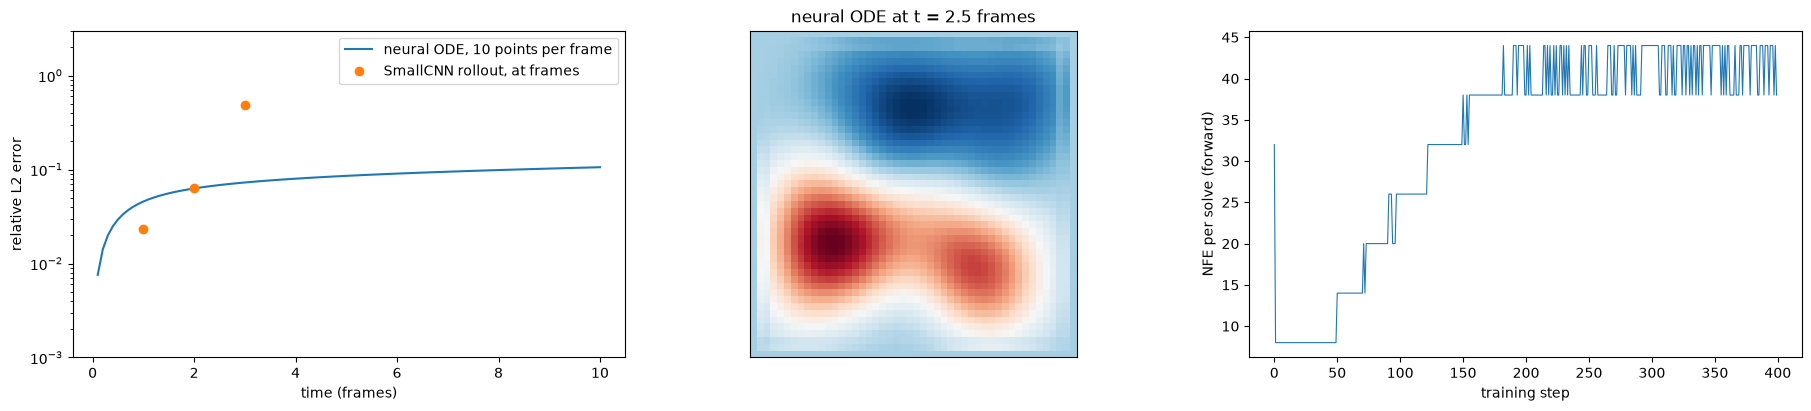

In [11]:
@torch.no_grad()
def evaluate(k):
    u0 = torch.from_numpy(heat_fine[k, :1])[:, None]; tru = heat_fine[k]
    p = odeint(f, u0, torch.tensor(fine, dtype=torch.float32), rtol=1e-5, atol=1e-7 * scale)[:, 0, 0].numpy()
    d = [u0[0, 0].numpy()]; u = u0
    for _ in range(10):
        u = disc(u); d.append(u[0, 0].numpy())
    d = np.stack(d)
    rel = lambda z, y: np.linalg.norm((z - y).reshape(len(z), -1), axis=1) / np.linalg.norm(y.reshape(len(y), -1), axis=1)
    return rel(p, tru), rel(d, tru[::10]), p

res = [evaluate(k) for k in range(len(test_a))]
e_node = np.mean([r[0] for r in res], 0); e_disc = np.mean([r[1] for r in res], 0)

fig, ax = plt.subplots(1, 3, figsize=(18, 4), layout="constrained")
ax[0].semilogy(fine[1:] / dt, e_node[1:], label="neural ODE, 10 points per frame")
ax[0].semilogy(np.arange(1, 11), e_disc[1:], "o", label="SmallCNN rollout, at frames")
ax[0].set_ylim(1e-3, 3); ax[0].set_xlabel("time (frames)"); ax[0].set_ylabel("relative L2 error"); ax[0].legend()
j = 25                                          # t = 2.5 frames: between two training frames
ax[1].imshow(res[0][2][j], cmap="RdBu_r", origin="lower"); ax[1].set_title(f"neural ODE at t = {fine[j] / dt:.1f} frames")
ax[2].plot(nfe_train, lw=0.8); ax[2].set_xlabel("training step"); ax[2].set_ylabel("NFE per solve (forward)")
for a in ax[1:2]: a.set_xticks([]); a.set_yticks([])
plt.show()

**What to observe**

* The neural ODE gives a state at every time, including between the training frames. The SmallCNN gives one per frame.
* Follow the SmallCNN dots for 10 frames. Is its rollout stable at this step size? (Hint: how much does mode $(6, 6)$ decay over one frame, and what happens to a one-step map that gets that factor slightly wrong?)
* How does the number of function evaluations change during training?

### Solver cost and stiffness

Now replace $f_\theta$ by the exact discretized right-hand side, $\alpha$ times the 5-point Laplacian (method of lines), and count how many function evaluations `dopri5` needs for the same time interval as the diffusivity grows.

In [12]:
def nfe_exact(alpha_, n=48, frames_=10):
    h = 1.0 / (n - 1); cnt = [0]
    lap = torch.tensor([[0, 1, 0], [1, -4, 1], [0, 1, 0]], dtype=torch.float64)[None, None] / h**2
    def rhs(t, u):
        cnt[0] += 1
        return alpha_ * F.conv2d(u, lap, padding=1)
    xx = np.linspace(0, 1, n); XX, YY = np.meshgrid(xx, xx)
    u0 = torch.from_numpy(np.sin(np.pi * XX) * np.sin(np.pi * YY) + 0.3 * np.sin(3 * np.pi * XX) * np.sin(2 * np.pi * YY))[None, None]
    odeint(rhs, u0, torch.tensor([0.0, frames_ * dt], dtype=torch.float64), rtol=1e-4, atol=1e-8)
    return cnt[0]

alphas = [0.25, 0.5, 1, 2, 4]
counts = [nfe_exact(a) for a in alphas]
for a, c in zip(alphas, counts):
    print(f"alpha = {a:5.2f}   NFE = {c}")

alpha =  0.25   NFE = 260
alpha =  0.50   NFE = 506
alpha =  1.00   NFE = 1010
alpha =  2.00   NFE = 2000
alpha =  4.00   NFE = 3992


**What to observe**

* How does NFE scale with $\alpha$? Compare with the forward Euler stability limit $\Delta t \le h^2 / (4\alpha)$.
* The learned $f_\theta$ in the previous section used far fewer evaluations than the exact right-hand side at $\alpha = 1$. The data contain only modes up to 6. Why does that matter for the solver?

---
## Exercises

1. **ConvLSTM.** Write a `ConvLSTM` class with a cell state and forget, input and output gates (initialize the forget-gate bias to 1). Compare it with the ConvGRU at the same number of parameters.
2. **Adjoint.** Replace `odeint` by `torchdiffeq.odeint_adjoint` in `train_node` (the model must then be an `nn.Module`, which it is). Compare the time per step, and the gradient of the loss with respect to the first convolution's weights for one batch.
3. **Irregular sampling.** Generate training trajectories at random times instead of every `dt` (for example, 20 sorted uniform times in $[0, 20\,dt]$, different for each trajectory) and train the neural ODE on them. The SmallCNN cannot be trained on such data without interpolation. How much does the neural ODE's error change?

In [13]:
# Exercise 2 starter
class ConvLSTM(Base):
    def __init__(self, c, hidden=16):
        super().__init__(c)
        # TODO: encoder, one convolution producing the 4 gates (f, i, o, candidate), decoder
        raise NotImplementedError